# Single-cell atlas of HPV-negative oral cavity lesions: normal mucosa, leukoplakia and OSCC

Re-analysis of the single-cell RNA-seq dataset **GSE181919** (Choi et al., *Nat Commun* 2023), restricted to
**HPV-negative oral cavity** samples: normal mucosa (NL), leukoplakia (LP) and primary carcinoma (CA).

**Aim.** Build a clean, annotated reference of these tissues as the basis for finding epithelial genes that
separate tumour from normal epithelium across patients (candidate markers for a surgical margin test).

**Contents**
1. Setup
2. Load data
3. Quality control
4. Doublet scoring
5. Normalization and highly variable genes
6. PCA
7. Neighbour graph and UMAP (before integration)
8. Data checks: keratins, ambient RNA, cell numbers
9. Integration with Harmony
10. Clustering and annotation
11. Next steps

## 1. Setup

In [ ]:
from pathlib import Path
import time

import anndata as ad
import harmonypy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns
from scipy.special import logit
from scipy.stats import median_abs_deviation
from sklearn.neighbors import NearestNeighbors

sc.settings.verbosity = 0
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

DATA_DIR = Path("data")         # GEO supplementary files of GSE181919
RESULTS_DIR = Path("results")   # .h5ad checkpoints (not tracked by git)
FIG_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def geo_file(name: str) -> Path:
    """Path of a GEO file in DATA_DIR, gzipped or not."""
    for path in (DATA_DIR / name, DATA_DIR / f"{name}.gz"):
        if path.exists():
            return path
    raise FileNotFoundError(f"{name}(.gz) not found in {DATA_DIR}/ (see README)")

## 2. Load data

GEO provides a cell metadata table (patient, sample, tissue type, subsite, HPV status and the authors'
cell-type labels) and a dense UMI count matrix (genes × cells) as text.

In [ ]:
meta = pd.read_csv(geo_file("GSE181919_Barcode_metadata.txt"), sep="\t", index_col=0)
print(meta.shape)
meta.head()

(54239, 8)


,patient.id,sample.id,Gender,Age,tissue.type,subsite,hpv,cell.type
AAACGGGCATGACGGA-1,P4,C04,F,58,CA,OC,HPV-,T.cells
AAAGATGAGCAGACTG-1,P4,C04,F,58,CA,OC,HPV-,T.cells
AAAGATGAGTGTACTC-1,P4,C04,F,58,CA,OC,HPV-,Malignant.cells
AAAGATGCACTCTGTC-1,P4,C04,F,58,CA,OC,HPV-,Malignant.cells
AAAGCAAAGACAGGCT-1,P4,C04,F,58,CA,OC,HPV-,Malignant.cells


In [ ]:
print(meta.index[:5])            # cell barcodes
print(meta.index.is_unique)
for col in meta.columns:
    print(col, meta[col].nunique(), meta[col].unique()[:8])

Index(['AAACGGGCATGACGGA-1', 'AAAGATGAGCAGACTG-1', 'AAAGATGAGTGTACTC-1',
       'AAAGATGCACTCTGTC-1', 'AAAGCAAAGACAGGCT-1'],
      dtype='str')
True
patient.id 23 <StringArray>
['P4', 'P15', 'P21', 'P22', 'P26', 'P30', 'P31', 'P38']
Length: 8, dtype: str
sample.id 37 <StringArray>
['C04', 'C15', 'C21', 'C22', 'C26', 'C30', 'C31', 'C38']
Length: 8, dtype: str
Gender 2 <StringArray>
['F', 'M']
Length: 2, dtype: str
Age 17 [58 56 69 50 57 54 66 73]
tissue.type 4 <StringArray>
['CA', 'LN', 'NL', 'LP']
Length: 4, dtype: str
subsite 3 <StringArray>
['OC', 'OP', 'HP']
Length: 3, dtype: str
hpv 2 <StringArray>
['HPV-', 'HPV+']
Length: 2, dtype: str
cell.type 10 <StringArray>
[          'T.cells',   'Malignant.cells',    'B_Plasma.cells',
 'Endothelial.cells',       'Fibroblasts',       'Macrophages',
   'Dendritic.cells',        'Mast.cells']
Length: 8, dtype: str


The count matrix is a dense text file of about 20,000 genes × 54,000 cells. Reading it in chunks and
converting each chunk to a sparse matrix keeps memory use low (takes about 6 minutes).

In [ ]:
def read_counts_sparse(path, sep="\t", chunksize=500):
    """Read a dense text count matrix into a sparse matrix, 500 rows at a time."""
    blocks, row_names, col_names = [], [], None
    t0 = time.time()
    reader = pd.read_csv(path, sep=sep, index_col=0, chunksize=chunksize)
    for i, chunk in enumerate(reader):
        if col_names is None:
            col_names = chunk.columns.astype(str)
        blocks.append(sp.csr_matrix(chunk.to_numpy(dtype=np.float32)))
        row_names.extend(chunk.index.astype(str))
        if i % 10 == 0:
            print(f"  {len(row_names):>7,} rows read  ({time.time() - t0:.0f} s)")
    X = sp.vstack(blocks).tocsr()
    print(f"Done: {X.shape[0]:,} {X.shape[1]:,}, {X.nnz:,} non-zeros, {time.time() - t0:.0f} s")
    return X, pd.Index(row_names), pd.Index(col_names)

In [ ]:
X, genes, barcodes = read_counts_sparse(geo_file("GSE181919_UMI_counts.txt"))
print(genes[:5])      # rows are genes
print(barcodes[:5])   # columns are cell barcodes

      500 rows read  (10 s)
    5,500 rows read  (97 s)
   10,500 rows read  (190 s)
   15,500 rows read  (281 s)
Done: 20,000 × 54,239, 117,812,072 non-zeros, 363 s
Index(['RP11-34P13.7', 'FO538757.2', 'AP006222.2', 'RP4-669L17.10',
       'RP11-206L10.9'],
      dtype='str')
Index(['AAACGGGCATGACGGA.1', 'AAAGATGAGCAGACTG.1', 'AAAGATGAGTGTACTC.1',
       'AAAGATGCACTCTGTC.1', 'AAAGCAAAGACAGGCT.1'],
      dtype='str')


In [ ]:
# The count matrix writes barcodes with "." where the metadata uses "-"
barcodes = barcodes.str.replace(".", "-", regex=False)

# Cells x genes. Object-dtype indexes keep the gene names intact when the
# object is saved to .h5ad (pandas' newer string dtype did not survive the round trip).
adata = ad.AnnData(
    X=X.T.tocsr(),
    obs=pd.DataFrame(index=barcodes.astype(object)),
    var=pd.DataFrame(index=genes.astype(object)),
)
adata.var_names_make_unique()
adata.obs = adata.obs.join(meta)

In [ ]:
adata[:5, :5].to_df()

,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP11-206L10.9
AAACGGGCATGACGGA-1,0.0,1.0,0.0,0.0,0.0
AAAGATGAGCAGACTG-1,0.0,3.0,0.0,0.0,0.0
AAAGATGAGTGTACTC-1,0.0,0.0,0.0,0.0,0.0
AAAGATGCACTCTGTC-1,0.0,2.0,3.0,0.0,0.0
AAAGCAAAGACAGGCT-1,0.0,0.0,0.0,0.0,0.0


## 3. Quality control

QC follows the *single-cell best practices* approach (Heumos et al., 2023): flag cells that are outliers
by median absolute deviations (MAD) instead of fixed cut-offs. Thresholds are computed **per sample**,
because library size and quality differ between samples.

In [ ]:
# mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes.
adata.var["hb"] = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)")

In [ ]:
print("mitochondrial genes:", adata.var["mt"].sum())
print("ribosomal genes:    ", adata.var["ribo"].sum())
print("hemoglobin genes:   ", adata.var["hb"].sum())

In [ ]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True
)

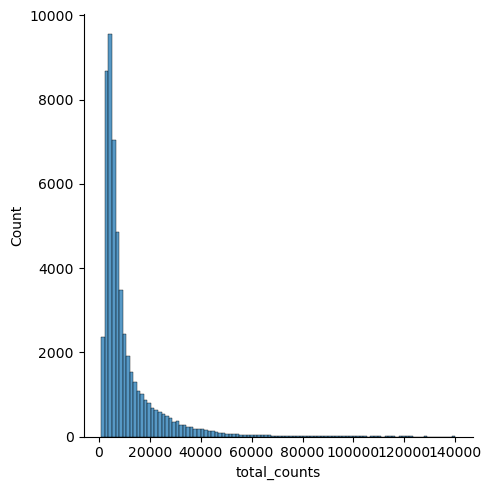

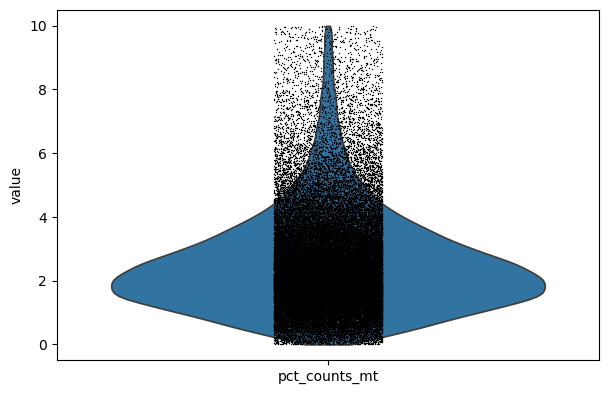

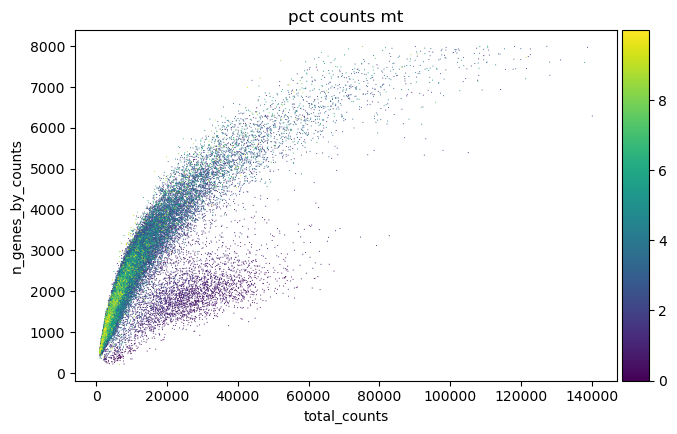

In [ ]:
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
p2 = sc.pl.violin(adata, "pct_counts_mt")
p3 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
def mad_thresholds(values: pd.Series, nmads: float) -> tuple[float, float]:
    """Thresholds `nmads` median absolute deviations below and above the median of `values`."""
    median, mad = np.median(values), median_abs_deviation(values)
    return median - nmads * mad, median + nmads * mad


def is_outlier_by_group(adata, metric, nmads, side="both", groupby="sample.id"):
    """Flag cells beyond the MAD thresholds of `metric`, computed separately for each sample."""
    def flag(v):
        lower, upper = mad_thresholds(v, nmads)
        return v > upper if side == "upper" else (v < lower) | (v > upper)
    return adata.obs.groupby(groupby, observed=True)[metric].transform(flag).astype(bool)


# Mitochondrial fraction on the logit scale, so MADs behave on a 0–1 proportion
mt_fraction = (adata.obs["total_counts_mt"] + 1) / (adata.obs["total_counts"] + 2)
adata.obs["logit_mt_fraction"] = logit(mt_fraction)

In [ ]:
qc_filters = {
    "log1p_total_counts": (5, "both"),
    "log1p_n_genes_by_counts": (5, "both"),
    "pct_counts_in_top_20_genes": (5, "both"),
    "logit_mt_fraction": (3, "upper"),
}

flags = {
    metric: is_outlier_by_group(adata, metric, nmads, side)
    for metric, (nmads, side) in qc_filters.items()
}
adata.obs["outlier"] = (
    flags["log1p_total_counts"]
    | flags["log1p_n_genes_by_counts"]
    | flags["pct_counts_in_top_20_genes"]
)
adata.obs["mt_outlier"] = flags["logit_mt_fraction"] & (adata.obs["pct_counts_mt"] > 8)
adata.obs[["outlier", "mt_outlier"]].value_counts()

outlier  mt_outlier
False    False         49035
True     False          4786
False    True            378
True     True             40
Name: count, dtype: int64

### Subset: oral cavity, HPV-negative

The dataset also contains other head and neck subsites and HPV-positive tumours, which have different
biology. I keep oral cavity (`OC`) HPV-negative samples only, and check that each tissue type still has
enough patients.

In [ ]:
oral = adata[(adata.obs["subsite"] == "OC") & (adata.obs["hpv"] == "HPV-")].copy()
print(oral)

# The crucial check: enough patients per tissue type?
print((pd.crosstab(oral.obs["patient.id"], oral.obs["tissue.type"]) > 0).sum())

AnnData object with n_obs × n_vars = 24156 × 20000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'patient.id', 'sample.id', 'Gender', 'Age', 'tissue.type', 'subsite', 'hpv', 'cell.type', 'outlier', 'mt_outlier'
tissue.type
CA    10
LP     4
NL     3
dtype: int64


In [ ]:
oral.obs[["outlier", "mt_outlier"]].value_counts()

outlier  mt_outlier
False    False         21935
True     False          1984
False    True            225
True     True             12
Name: count, dtype: int64

In [ ]:
print(f"Total number of cells: {oral.n_obs}")
oral = oral[(~oral.obs["outlier"]) & (~oral.obs["mt_outlier"])].copy()
print(f"Number of cells after filtering of low quality cells: {oral.n_obs}")

Total number of cells: 24156
Number of cells after filtering of low quality cells: 21935


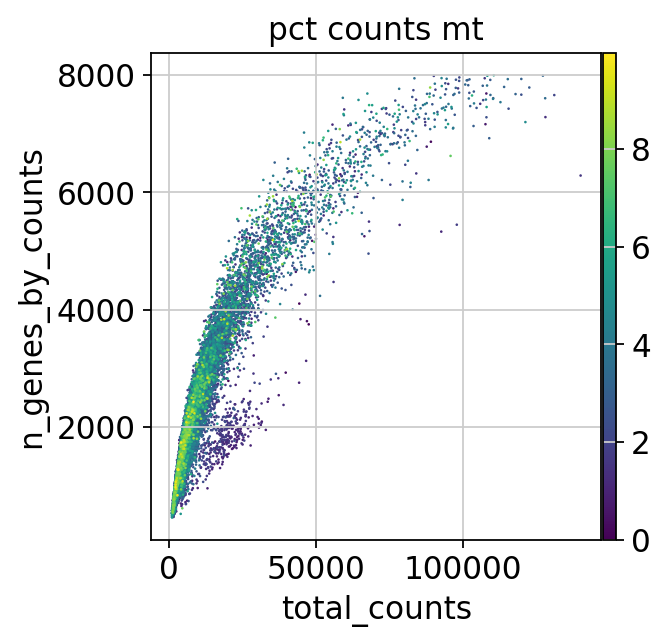

In [ ]:
p1 = sc.pl.scatter(oral, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

## 4. Doublet scoring

A doublet is a droplet that captured two cells, so its barcode mixes two expression profiles. Scrublet
simulates artificial doublets from the data and scores each barcode by its similarity to them. It must run on
raw counts, and per sample (`batch_key`), because doublets can only form within one sample's run.

In [ ]:
v = oral.X.data[:1_000_000]
print("raw counts in X:", np.allclose(v, np.round(v)))   # must be True

raw counts in X: True


In [ ]:
sc.pp.scrublet(oral, batch_key="sample.id")

In [ ]:
oral.obs.groupby("sample.id", observed=True)["predicted_doublet"].mean().sort_values().round(3)

sample.id
C06     0.001
LP16    0.001
LP33    0.003
C21     0.003
C51     0.003
LP17    0.003
C30     0.004
N15     0.004
C60     0.005
C07     0.006
C31     0.007
N06     0.007
C26     0.007
LP15    0.008
C04     0.009
N21     0.011
C15     0.012
Name: predicted_doublet, dtype: float64

In [ ]:
pd.crosstab(oral.obs["cell.type"], oral.obs["predicted_doublet"], normalize="index").round(3)

predicted_doublet,False,True
cell.type,,
B_Plasma.cells,0.992,0.008
Dendritic.cells,0.996,0.004
Endothelial.cells,0.988,0.012
Epithelial.cells,0.994,0.006
Fibroblasts,0.995,0.005
Macrophages,0.993,0.007
Malignant.cells,0.994,0.006
Mast.cells,1.000,0.000
Myocytes,0.976,0.024


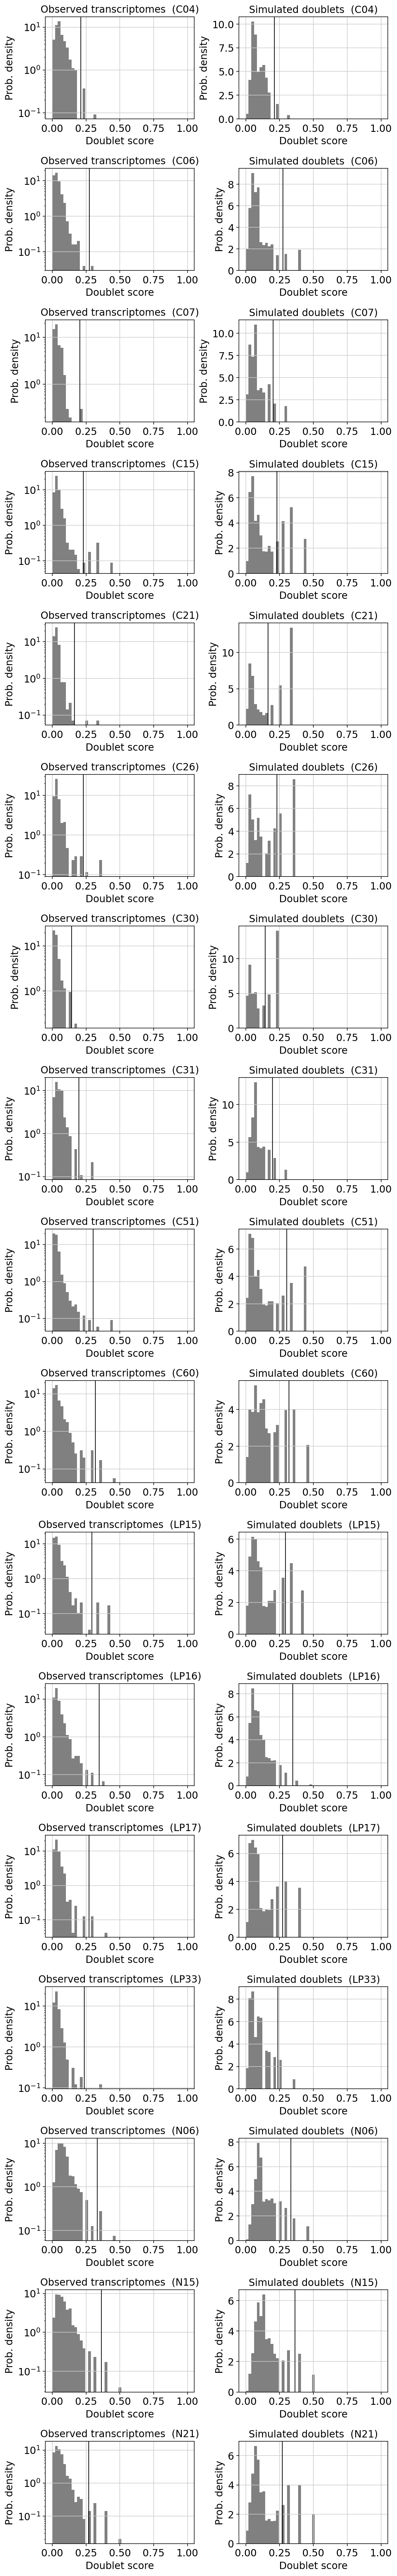

In [ ]:
sc.pl.scrublet_score_distribution(oral)

Scrublet predicts 126 doublets (0.6% of cells; at most 2.4% in any cell type).

> **Note:** in this version the predicted doublets are **flagged but not removed**
> (`oral.obs["predicted_doublet"]`). All results below use 21,935 cells. They must be removed before
> the pseudobulk differential expression step.

In [ ]:
oral.write_h5ad(RESULTS_DIR / "oral_qc.h5ad", compression="gzip")

## 5. Normalization and highly variable genes

Raw counts are kept in `layers["counts"]` (needed later for pseudobulk). `X` holds library-size-normalized,
log1p-transformed values, also copied to `layers["log1p_norm"]`.

In [ ]:
oral.layers["counts"] = oral.X.copy()
sc.pp.normalize_total(oral)
sc.pp.log1p(oral)
oral.layers["log1p_norm"] = oral.X.copy()

In [ ]:
cells = oral.obs_names[:5]
raw  = oral[cells, :8].to_df(layer="counts")
norm = oral[cells, :8].to_df(layer="log1p_norm")

print("RAW COUNTS");   display(raw)
print("NORMALIZED");   display(norm.round(2))

RAW COUNTS


,0,1,2,3,4,5,6,7
AAACGGGCATGACGGA-1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAGATGAGCAGACTG-1,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAGATGAGTGTACTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAGATGCACTCTGTC-1,0.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0
AAAGCAAAGACAGGCT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


NORMALIZED


,0,1,2,3,4,5,6,7
AAACGGGCATGACGGA-1,0.0,0.11,0.00,0.0,0.0,0.0,0.0,0.0
AAAGATGAGCAGACTG-1,0.0,0.27,0.00,0.0,0.0,0.0,0.0,0.0
AAAGATGAGTGTACTC-1,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
AAAGATGCACTCTGTC-1,0.0,0.18,0.26,0.0,0.0,0.0,0.0,0.0
AAAGCAAAGACAGGCT-1,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0


Gene variance grows with mean expression, so HVGs are ranked by **normalized dispersion** (dispersion
compared with genes of similar mean). HVGs are selected **within each sample** and genes variable in many
samples are preferred, so that sample-specific technical variation does not drive the selection.

In [ ]:
sc.pp.highly_variable_genes(
    oral,
    n_top_genes=3000,
    flavor="seurat",
    batch_key="sample.id",
)

HVGs selected: 3000
        highly_variable  highly_variable_nbatches     means
PTPRC              True                         9  0.634430
EPCAM             False                         4  0.046145
CD3E               True                        12  0.595583
KRT5               True                        15  1.004529
CD68               True                        15  0.611082
KRT13              True                        12  0.182424
KRT14              True                        16  1.803514
COL1A1             True                        17  1.948453
PECAM1             True                        15  0.344301
count    3000.000000
mean       10.427667
std         3.523385
min         5.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        17.000000
Name: highly_variable_nbatches, dtype: float64


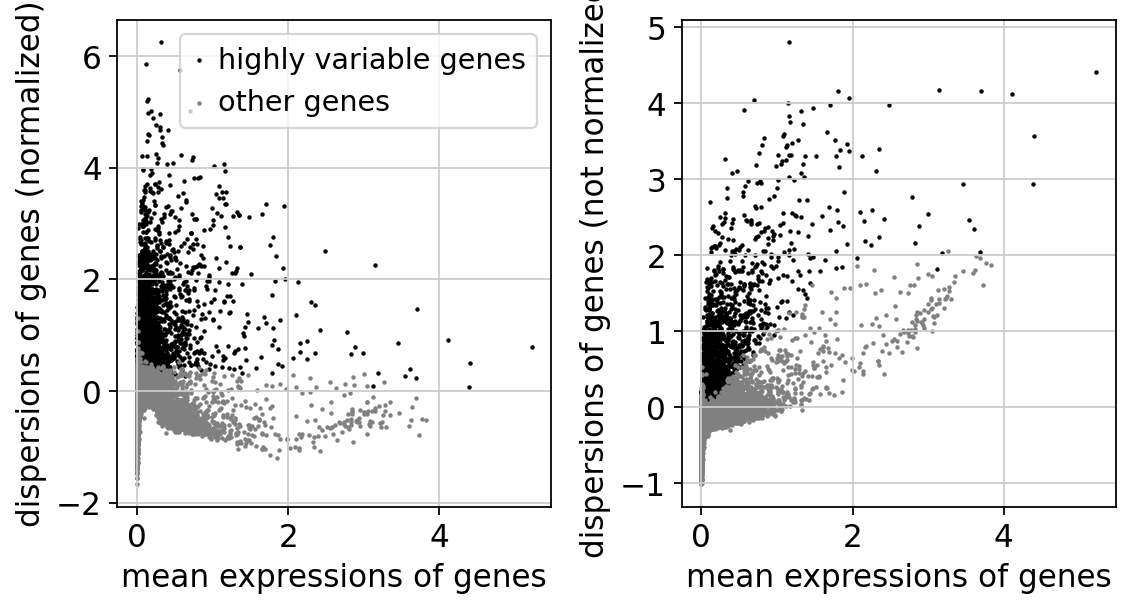

In [ ]:
print("HVGs selected:", oral.var["highly_variable"].sum())

# Are known cell-type markers among them?
markers = ["KRT5", "KRT13", "KRT14", "CD3E", "PTPRC", "COL1A1", "EPCAM", "CD68", "PECAM1"]
print(oral.var.loc[oral.var_names.isin(markers), ["highly_variable", "highly_variable_nbatches", "means"]])

# How many samples did the chosen genes come from?
print(oral.var.loc[oral.var["highly_variable"], "highly_variable_nbatches"].describe())

sc.pl.highly_variable_genes(oral)

In [ ]:
# Mitochondrial and ribosomal genes excluded from HVGs, to avoid structure driven by cell quality.
hvg = oral.var["highly_variable"]
is_mt   = oral.var_names.str.startswith("MT-")
is_ribo = oral.var_names.str.startswith(("RPS", "RPL"))
print("MT genes among HVGs:  ", (hvg & is_mt).sum())
print("Ribo genes among HVGs:", (hvg & is_ribo).sum())

# Remove them from the HVG list (the genes stay in the data, just not used for PCA)
oral.var.loc[is_mt | is_ribo, "highly_variable"] = False
print("HVGs now:", oral.var["highly_variable"].sum())

MT genes among HVGs:   0
Ribo genes among HVGs: 0
HVGs now: 2997


## 6. PCA

In [ ]:
sc.pp.pca(oral, n_comps=50, mask_var="highly_variable")

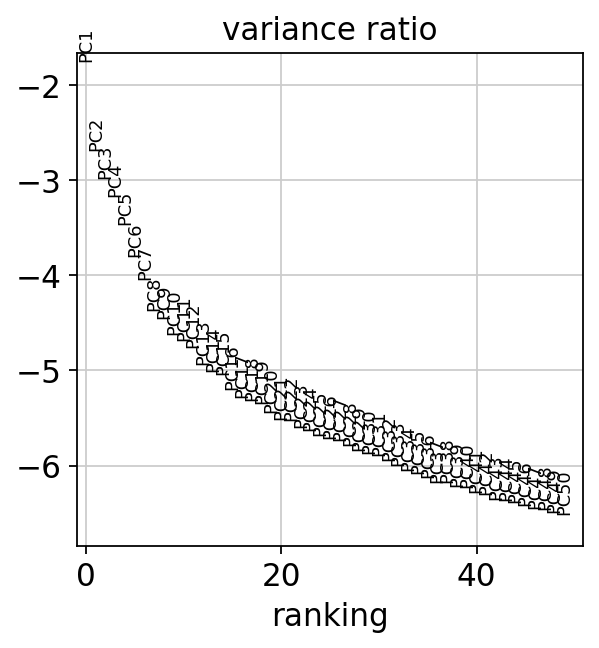

In [ ]:
sc.pl.pca_variance_ratio(oral, n_pcs=50, log=True)

In [ ]:
loadings = pd.DataFrame(oral.varm["PCs"][:, :5], index=oral.var_names,
                        columns=[f"PC{i+1}" for i in range(5)])
for pc in loadings.columns:
    s = loadings[pc].sort_values()
    print(f"{pc}  low side: {s.index[:6].tolist()}")
    print(f"{pc} high side: {s.index[-6:].tolist()}\n")

PC1  low side: ['SRGN', 'CD74', 'HLA-DRA', 'CREM', 'HLA-DRB1', 'HLA-DPA1']
PC1 high side: ['COL1A1', 'APOD', 'GSN', 'COL1A2', 'CFD', 'DCN']

PC2  low side: ['IL32', 'TRAC', 'CD3D', 'CCL5', 'CD52', 'CXCR4']
PC2 high side: ['TYROBP', 'CST3', 'FTL', 'CD74', 'CXCL8', 'HLA-DRA']

PC3  low side: ['KRT14', 'S100A2', 'IFI27', 'IGKC', 'KRT17', 'KRT6A']
PC3 high side: ['S100A4', 'MGP', 'MFAP4', 'GSN', 'APOD', 'CFD']

PC4  low side: ['ADIRF', 'GSN', 'IFI27', 'HSPB1', 'KRT14', 'RAMP2']
PC4 high side: ['LGALS1', 'IGKC', 'LUM', 'COL1A2', 'COL3A1', 'COL1A1']

PC5  low side: ['IGFBP7', 'GNG11', 'VIM', 'CRIP2', 'CD74', 'SPARCL1']
PC5 high side: ['CFD', 'KRT5', 'KRT6A', 'KRT17', 'S100A2', 'KRT14']



The top PCs separate the main lineages (immune/antigen-presenting vs fibroblast, T cell vs myeloid,
keratinocyte vs stroma). Below, PC1–PC2 coloured by the authors' cell types (should separate), by sample
(separation within a cell type = batch effect) and by mitochondrial % (should not follow a PC).

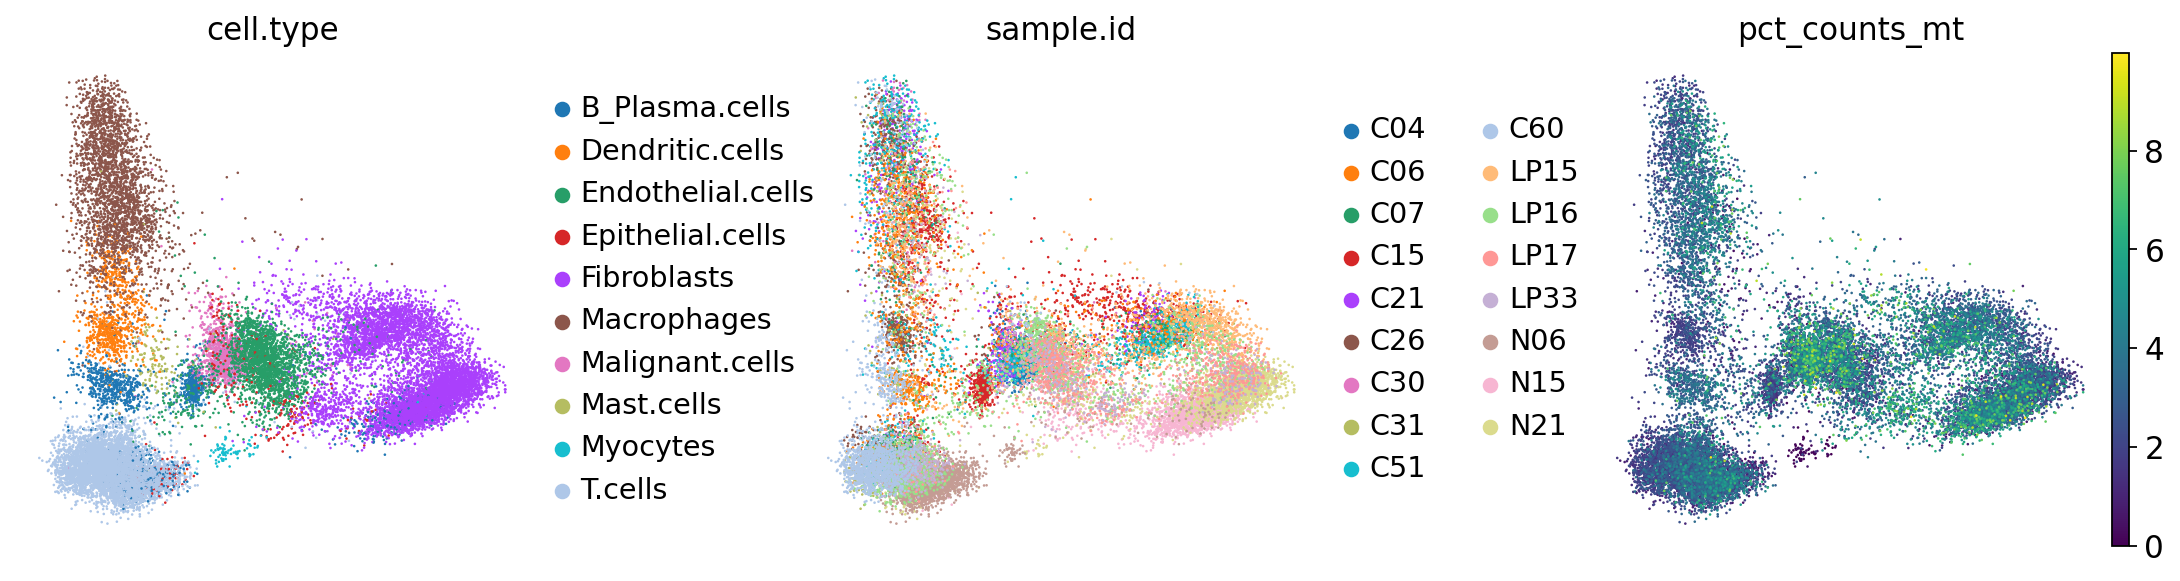

In [ ]:
sc.pl.pca(oral, color=["cell.type", "sample.id", "pct_counts_mt"], ncols=3, wspace=0.4)

## 7. Neighbour graph and UMAP (before integration)

A 15-nearest-neighbour graph is built on the first 40 PCs; UMAP draws this graph in 2D. UMAP is used only
for visualisation: distances between islands and island sizes are not interpreted. Clustering and DE use
the graph, PCA or expression values.

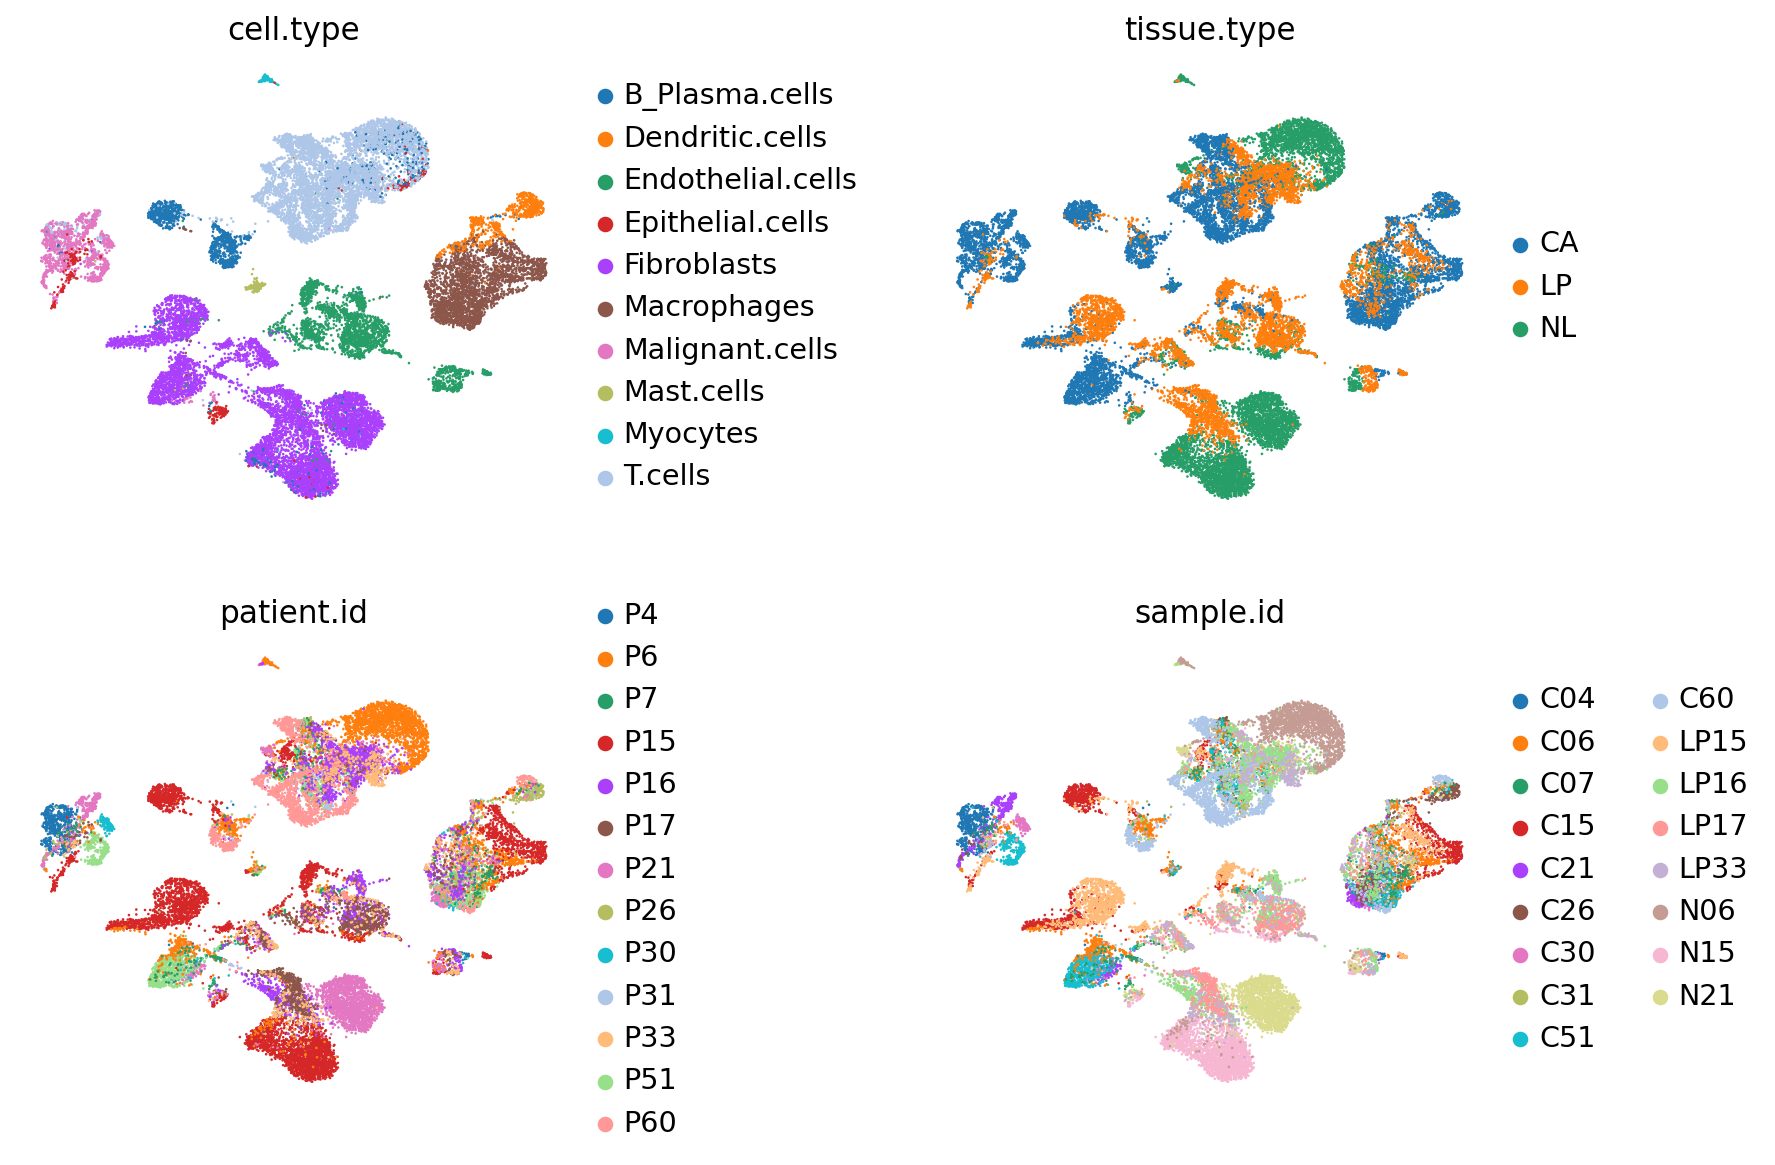

In [ ]:
sc.pp.neighbors(oral, n_neighbors=15, n_pcs=40)
sc.tl.umap(oral)
sc.pl.umap(oral, color=["cell.type", "tissue.type", "patient.id", "sample.id"], ncols=2, wspace=0.5)

Expected pattern: immune and stromal cells from different patients mix, while malignant cells separate by
patient. Normal cells share the same genetic program across people; each tumour carries its own mutations
and copy-number changes, which give it a patient-specific expression profile. Two consequences:

- integration must not force tumour cells from different patients together;
- a useful margin marker must be up in tumours of **most** patients, so marker testing will be done per
  patient (pseudobulk).

## 8. Data checks

### Keratins

In [ ]:
genes = ["KRT13", "KRT5", "IGKC", "JCHAIN", "COL1A1"]
df = sc.get.obs_df(oral, keys=genes + ["cell.type"], layer="counts")
print(df.groupby("cell.type", observed=True)[genes].apply(lambda x: (x > 0).mean()).round(2))

                   KRT13  KRT5  IGKC  JCHAIN  COL1A1
cell.type                                           
B_Plasma.cells      0.14  0.16  0.75    0.39    0.42
Dendritic.cells     0.05  0.47  0.96    0.63    0.26
Endothelial.cells   0.03  0.16  0.64    0.09    0.28
Epithelial.cells    0.26  0.39  0.48    0.16    0.34
Fibroblasts         0.04  0.14  0.51    0.11    0.90
Macrophages         0.06  0.32  0.85    0.18    0.40
Malignant.cells     0.20  0.98  0.92    0.29    0.67
Mast.cells          0.02  0.28  0.91    0.15    0.43
Myocytes            0.00  0.02  0.15    0.02    0.11
T.cells             0.02  0.13  0.59    0.06    0.12


KRT5 (basal keratin) is detected in 98% of malignant cells. KRT13 (a differentiation keratin of the upper
layers of normal oral mucosa) is mostly absent from them. This fits OSCC cells keeping a basal-like state and
losing normal maturation; loss of KRT13 has been reported in oral cancer. Loss of a normal marker can be as
useful for a margin test as gain of a tumour marker.

### Ambient RNA

In [ ]:
df = sc.get.obs_df(oral, keys=["IGKC", "KRT5", "COL1A1", "cell.type"], layer="counts")
print(df.groupby("cell.type", observed=True)[["IGKC", "KRT5", "COL1A1"]].median())

                   IGKC   KRT5  COL1A1
cell.type                             
B_Plasma.cells     22.0    0.0     0.0
Dendritic.cells    13.0    0.0     0.0
Endothelial.cells   1.0    0.0     0.0
Epithelial.cells    0.0    0.0     0.0
Fibroblasts         1.0    0.0     8.0
Macrophages         5.0    0.0     0.0
Malignant.cells    12.0  171.0     1.0
Mast.cells          4.0    0.0     0.0
Myocytes            0.0    0.0     0.0
T.cells             1.0    0.0     0.0


Malignant cells carry a median of 12 IGKC UMIs, close to the B/plasma group (22; this group mixes B cells,
which make little IGKC, with plasma cells, which make a lot). Tumour cells do not make antibodies, so this is
ambient RNA ("soup") from lysed plasma cells. Normal epithelial cells have a median of 0, because normal
mucosa contains fewer plasma cells.

This matters for DE: comparing tumour with normal epithelium would report IGKC, and every other gene abundant
in the tumour soup, as a "tumour marker". The plot below checks that IGKC in malignant cells follows the
plasma-cell share of each sample.

In [ ]:
df = sc.get.obs_df(oral, keys=["IGKC", "cell.type", "sample.id"], layer="counts")
mal = df[df["cell.type"] == "Malignant.cells"]
print(mal.groupby("sample.id", observed=True)["IGKC"].median().sort_values())

plasma_share = (oral.obs["cell.type"] == "B_Plasma.cells").groupby(oral.obs["sample.id"], observed=True).mean()
print(plasma_share.sort_values().round(3))

sample.id
C21      1.0
C26      3.0
C31      5.0
C60      6.0
C07      9.0
C51     13.0
C04     15.0
C30     15.0
C06     38.0
C15    198.0
Name: IGKC, dtype: float32
sample.id
LP17    0.001
C30     0.004
C21     0.006
C51     0.008
C26     0.016
LP33    0.018
C07     0.020
C04     0.021
LP16    0.026
N21     0.027
LP15    0.030
N15     0.045
C31     0.087
N06     0.099
C60     0.115
C06     0.158
C15     0.288
Name: cell.type, dtype: float64


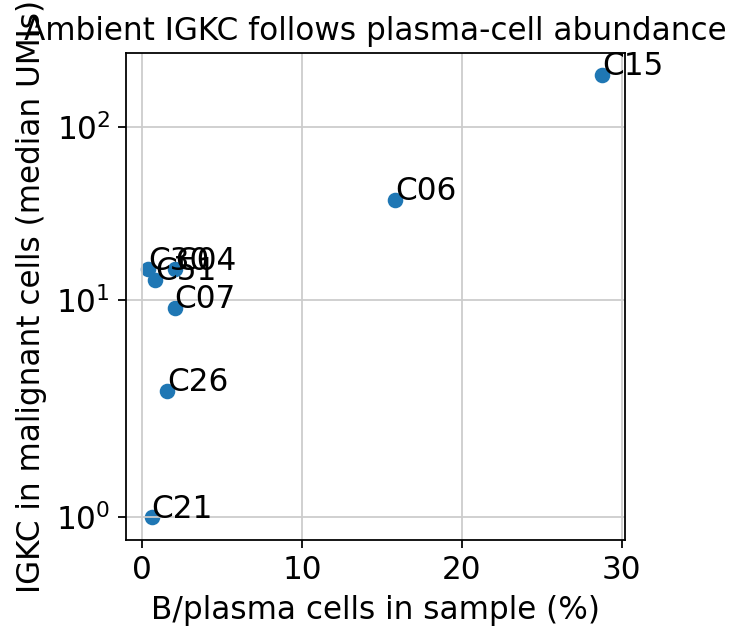

In [ ]:
igkc = mal.groupby("sample.id", observed=True)["IGKC"].median()
n_mal = mal.groupby("sample.id", observed=True).size()
tab = pd.DataFrame({"IGKC_malignant": igkc, "plasma_share": plasma_share, "n_malignant": n_mal}).dropna()
tab = tab[tab["n_malignant"] >= 10]               # leave out tumours with too few cells

plt.scatter(tab["plasma_share"] * 100, tab["IGKC_malignant"])
for s, r in tab.iterrows():
    plt.annotate(s, (r["plasma_share"] * 100, r["IGKC_malignant"]))
plt.xlabel("B/plasma cells in sample (%)"); plt.ylabel("IGKC in malignant cells (median UMIs)")
plt.yscale("symlog"); plt.title("Ambient IGKC follows plasma-cell abundance")
plt.savefig(FIG_DIR / "ambient_igkc.png", dpi=150, bbox_inches="tight")

### Cell numbers per tissue

Normal mucosa is hard to dissociate, so normal samples give mostly immune and stromal cells. The
normal-vs-tumour epithelium comparison depends on how many epithelial cells each sample has.

In [ ]:
print(pd.crosstab(oral.obs["cell.type"], oral.obs["tissue.type"]))
print(pd.crosstab(oral.obs["sample.id"], oral.obs["cell.type"].isin(["Epithelial.cells", "Malignant.cells"])))

tissue.type          CA    LP    NL
cell.type                          
B_Plasma.cells      961   114   372
Dendritic.cells     654    91    19
Endothelial.cells   287  1541   540
Epithelial.cells      0   148   194
Fibroblasts        1583  1867  3656
Macrophages        2067   459   138
Malignant.cells    1183     0     0
Mast.cells          125     7     5
Myocytes              1     3    81
T.cells            2618  1334  1887
cell.type  False  True 
sample.id              
C04          118    412
C06         1182     37
C07          457     37
C15         1607     54
C21          423    261
C26          815     19
C30          165     92
C31          443      7
C51         1364    259
C60         1722      5
LP15        1345     69
LP16        2170     23
LP17        1127     31
LP33         774     25
N06         1865     85
N15         2462     77
N21         2371     32


- In tumour samples, every epithelial cell is labelled `Malignant.cells` by the authors. Tumours also contain
  some normal epithelium, so this is checked later with CNV inference.
- Pseudobulk rule of thumb: ≥3 samples per group and ≥10–20 cells per sample.
  - NL: 3 samples, 32–85 epithelial cells each (the minimum).
  - LP: 4 samples, 23–69 each.
  - CA: 10 samples, but C26 (19), C31 (7) and C60 (5) are too small, leaving 7–8 usable tumours.

The comparison is possible but small, so results will be candidate markers that need validation.

## 9. Integration with Harmony

Harmony corrects the PCA embedding for sample (`sample.id`). The unintegrated UMAP is kept for comparison.

In [ ]:
oral.obsm["X_umap_unintegrated"] = oral.obsm["X_umap"].copy()

In [ ]:
ho = harmonypy.run_harmony(oral.obsm["X_pca"], oral.obs, "sample.id")
oral.obsm["X_pca_harmony"] = np.asarray(ho.Z_corr)   # harmonypy >= 2: cells x PCs
print(oral.obsm["X_pca_harmony"].shape)

(21935, 50)


In [ ]:
sc.pp.neighbors(oral, use_rep="X_pca_harmony", n_pcs=40)   # graph on corrected PCs
sc.tl.umap(oral)

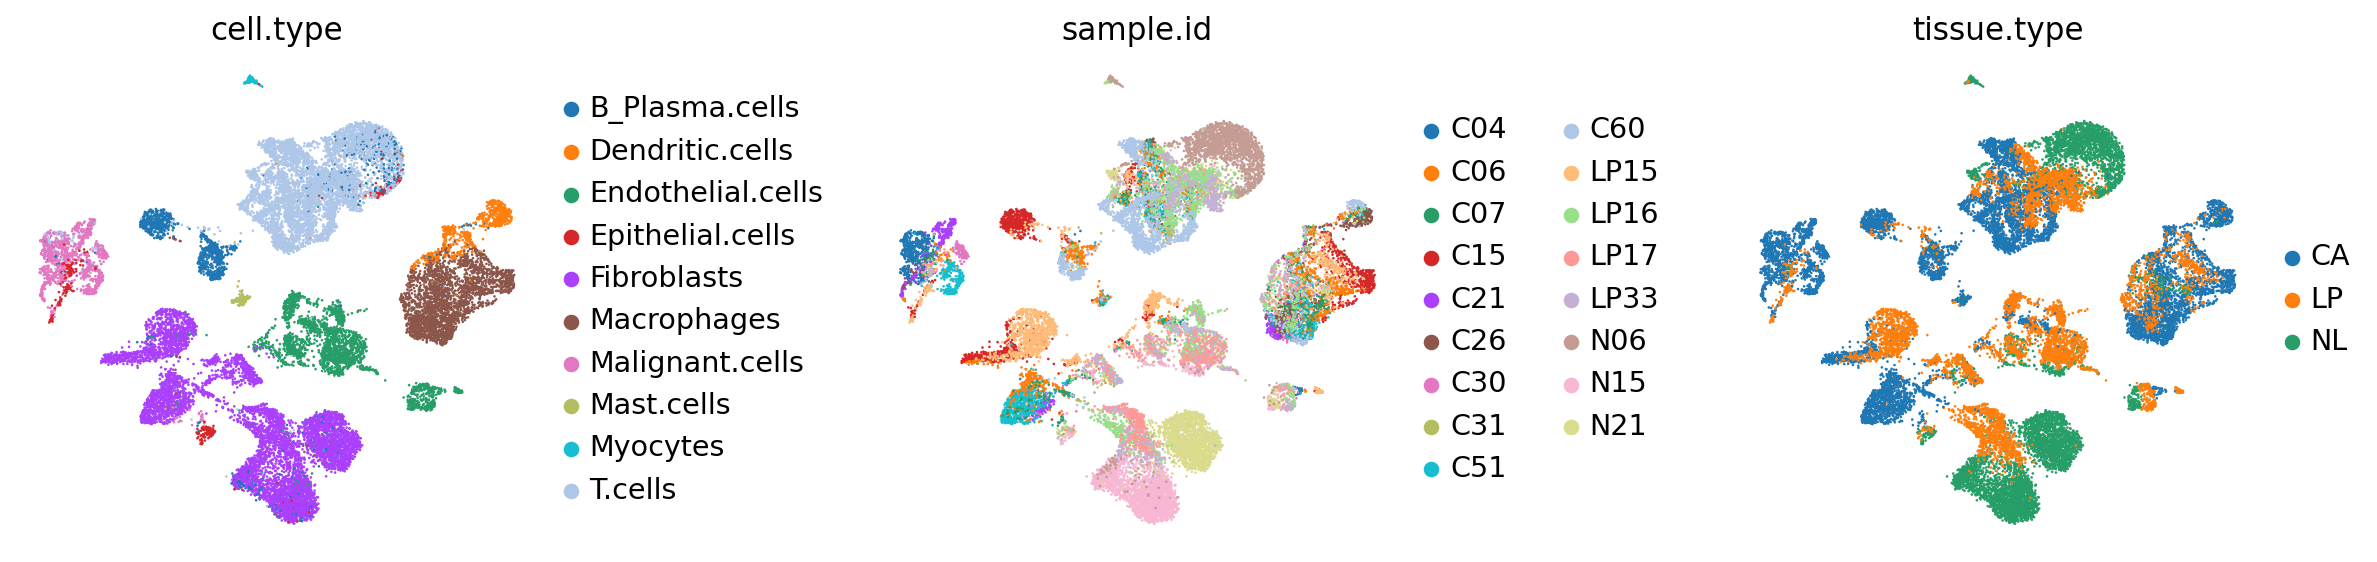

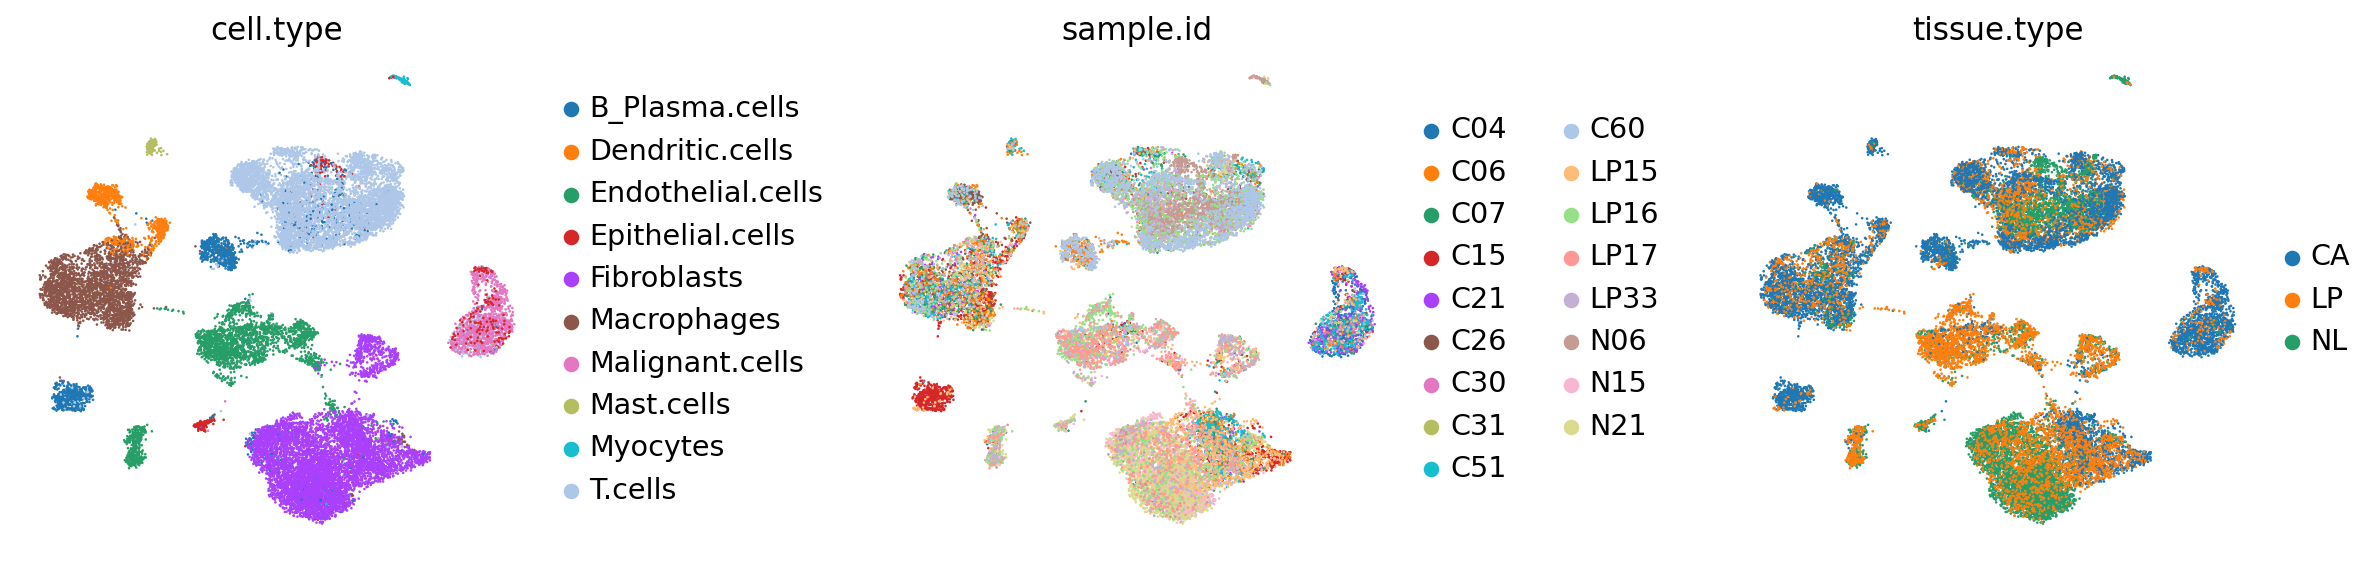

In [ ]:
for basis, when in [("umap_unintegrated", "before"), ("umap", "after")]:
    sc.pl.embedding(oral, basis=basis, color=["cell.type", "sample.id", "tissue.type"],
                    ncols=3, wspace=0.5, show=False)
    plt.savefig(FIG_DIR / f"umap_{when}_harmony.png", dpi=150, bbox_inches="tight")
    plt.show()

After Harmony, immune and stromal cells from different samples mix as expected, but the malignant cells
from different patients also mix, although they should stay partly separate. Harmony cannot tell biology from
batch, so it partly removed real tumour differences (over-integration). The neighbour test below measures this:
for each normal epithelial cell, the share of its 15 nearest epithelial neighbours that are malignant.

In [ ]:
from sklearn.neighbors import NearestNeighbors

epi = oral[oral.obs["cell.type"].isin(["Epithelial.cells", "Malignant.cells"])]
is_mal = (epi.obs["cell.type"] == "Malignant.cells").to_numpy()

def malignant_neighbors_of_normal(rep, k=15):
    X = epi.obsm[rep][:, :40]
    idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]  # [:,1:] skips the cell itself
    return is_mal[idx][~is_mal].mean()

print("Share of malignant cells among all epithelial cells:", is_mal.mean().round(2))
print("Malignant neighbors of normal cells, BEFORE Harmony:", malignant_neighbors_of_normal("X_pca").round(2))
print("Malignant neighbors of normal cells, AFTER Harmony: ", malignant_neighbors_of_normal("X_pca_harmony").round(2))

Share of malignant cells among all epithelial cells: 0.78
Malignant neighbors of normal cells, BEFORE Harmony: 0.16
Malignant neighbors of normal cells, AFTER Harmony:  0.37


The share of malignant neighbours around normal epithelial cells rises from 0.16 to 0.37 (complete mixing
would give 0.78). Each embedding is therefore used only for what it is good at:

| Task | Input |
|---|---|
| Clustering and broad cell-type labels | Harmony embedding |
| Malignant vs normal epithelium | CNV inference on expression values (no embedding) |
| Marker genes | Pseudobulk on raw counts (no embedding) |
| Tumour heterogeneity | Epithelial cells only, without Harmony |

Broad labels (epithelial, T cell, fibroblast…) are safe on the Harmony embedding: these lineages differ in
thousands of genes and stay separate after integration, and labels are assigned from marker expression,
which Harmony does not change. The fine label (malignant vs normal) is decided later by CNV inference.

In [ ]:
oral.write_h5ad(RESULTS_DIR / "oral_harmony.h5ad", compression="gzip")

## 10. Clustering and annotation

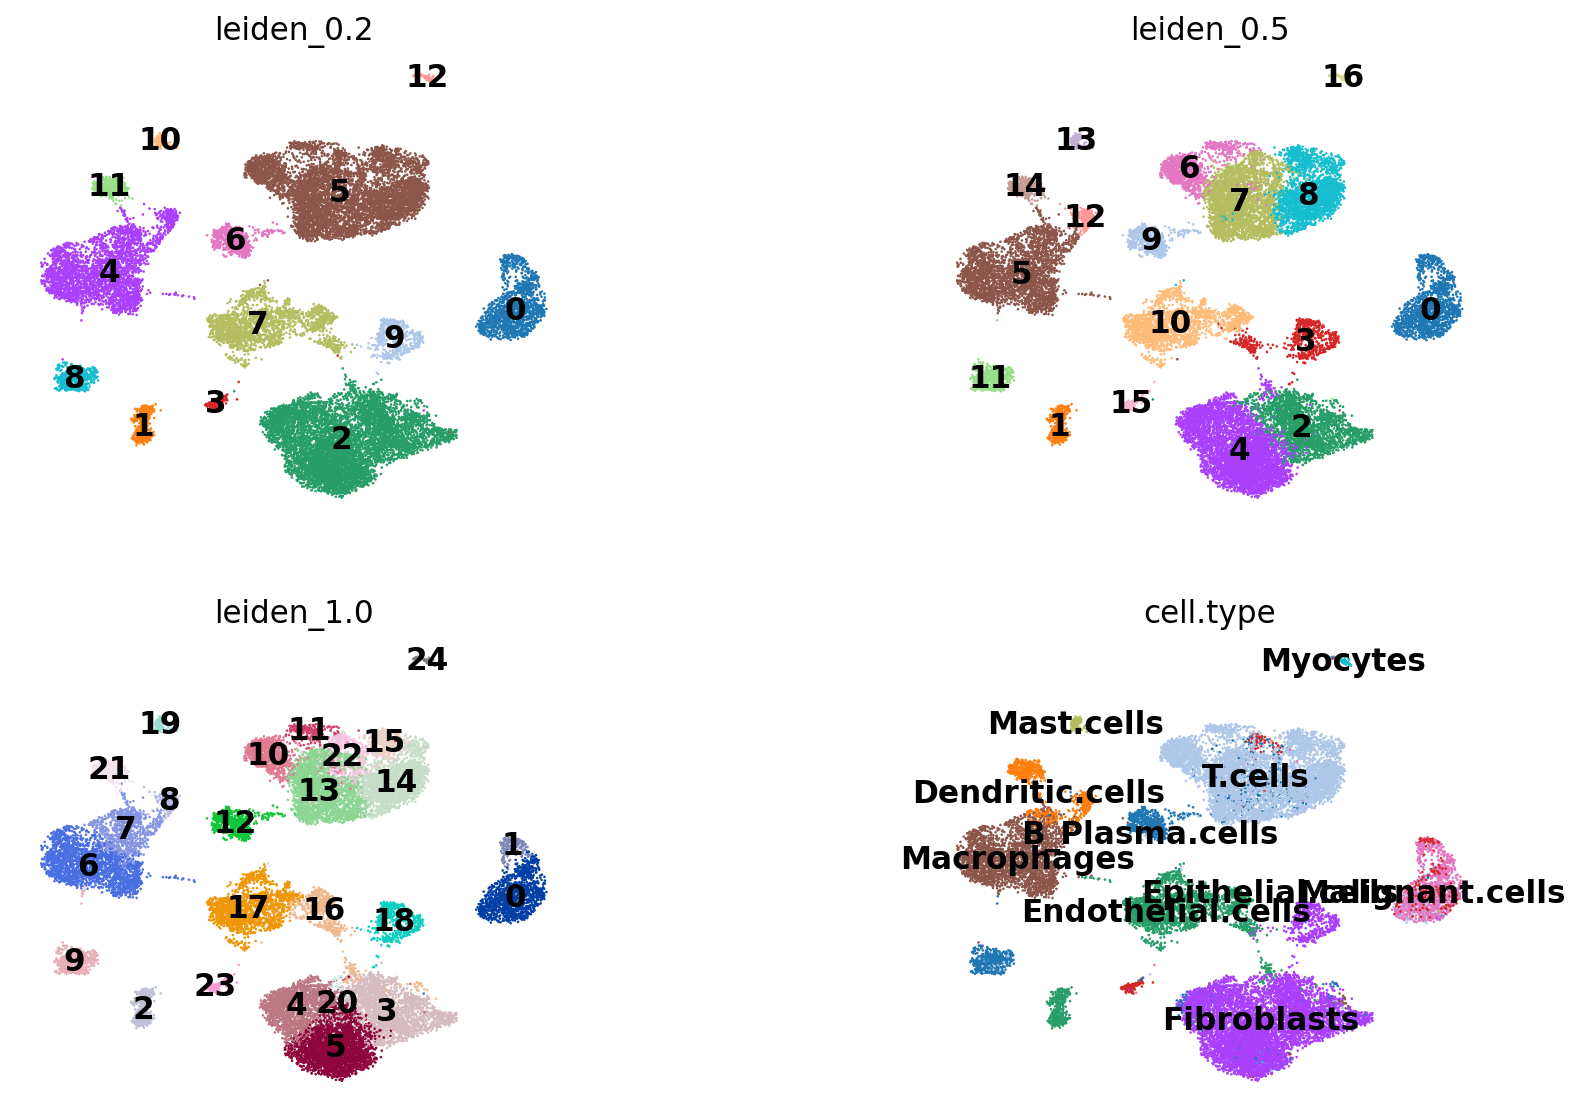

In [ ]:
for res in [0.2, 0.5, 1.0]:
    sc.tl.leiden(oral, resolution=res, key_added=f"leiden_{res}",
                 flavor="igraph", n_iterations=2, directed=False)

sc.pl.umap(oral, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "cell.type"],
           ncols=2, wspace=0.5, legend_loc="on data")

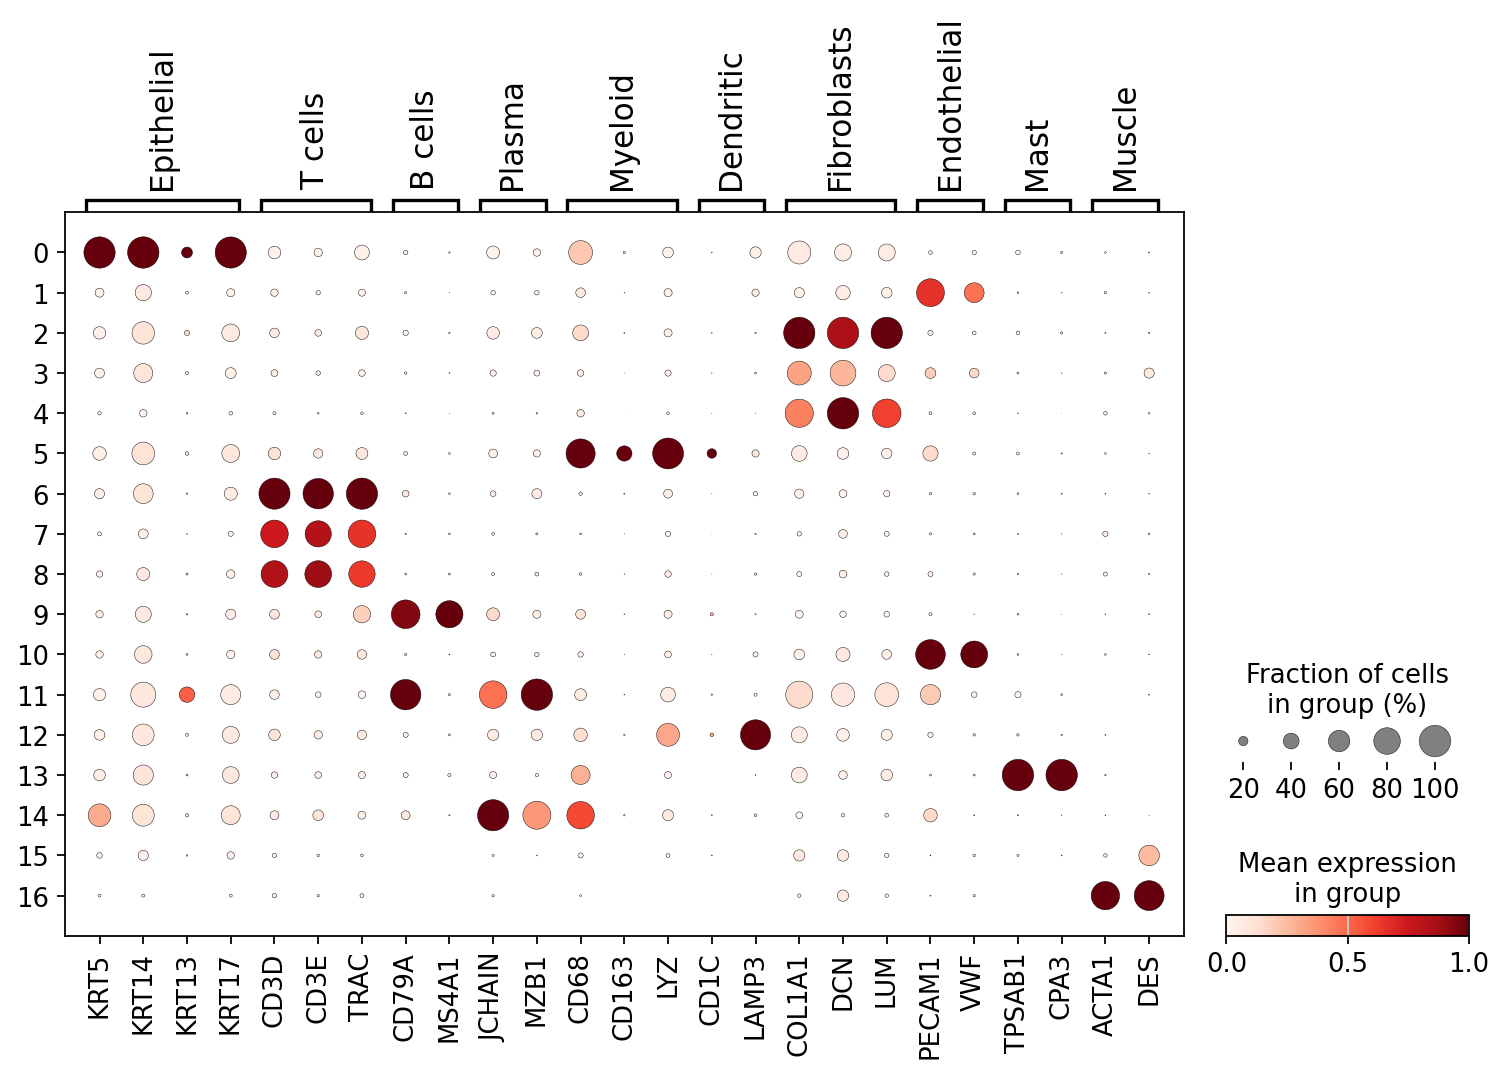

In [ ]:
markers = {
    "Epithelial":  ["KRT5", "KRT14", "KRT13", "KRT17"],
    "T cells":     ["CD3D", "CD3E", "TRAC"],
    "B cells":     ["CD79A", "MS4A1"],
    "Plasma":      ["JCHAIN", "MZB1"],
    "Myeloid":     ["CD68", "CD163", "LYZ"],
    "Dendritic":   ["CD1C", "LAMP3"],
    "Fibroblasts": ["COL1A1", "DCN", "LUM"],
    "Endothelial": ["PECAM1", "VWF"],
    "Mast":        ["TPSAB1", "CPA3"],
    "Muscle":      ["ACTA1", "DES"],
}
sc.pl.dotplot(oral, markers, groupby="leiden_0.5", standard_scale="var", show=False)
plt.savefig(FIG_DIR / "marker_dotplot.png", dpi=150, bbox_inches="tight")
plt.show()

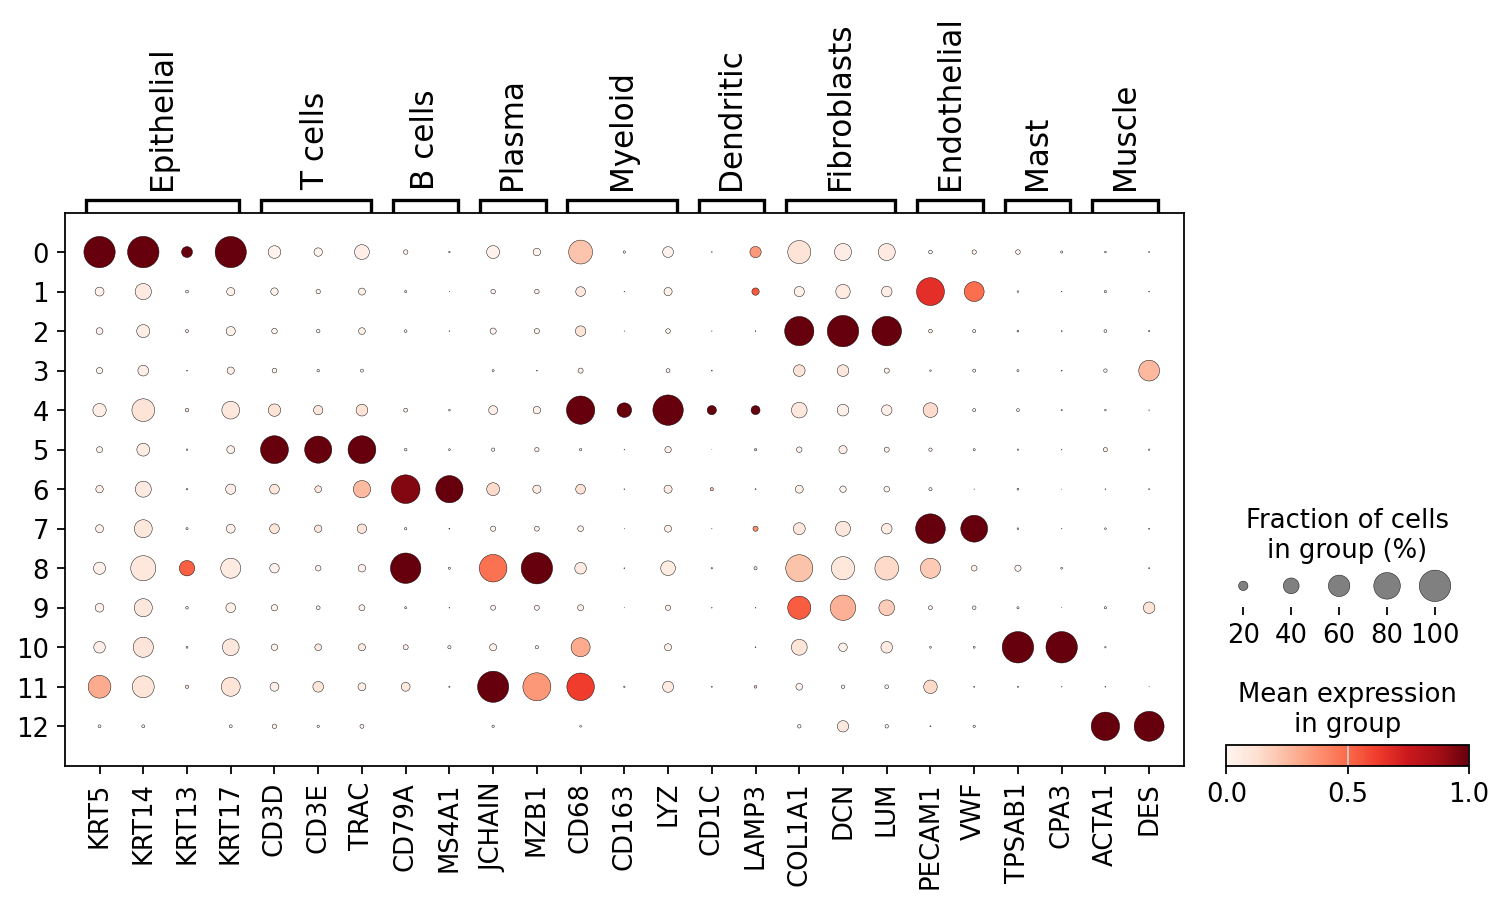

In [ ]:
sc.pl.dotplot(oral, markers, groupby="leiden_0.2", standard_scale="var")

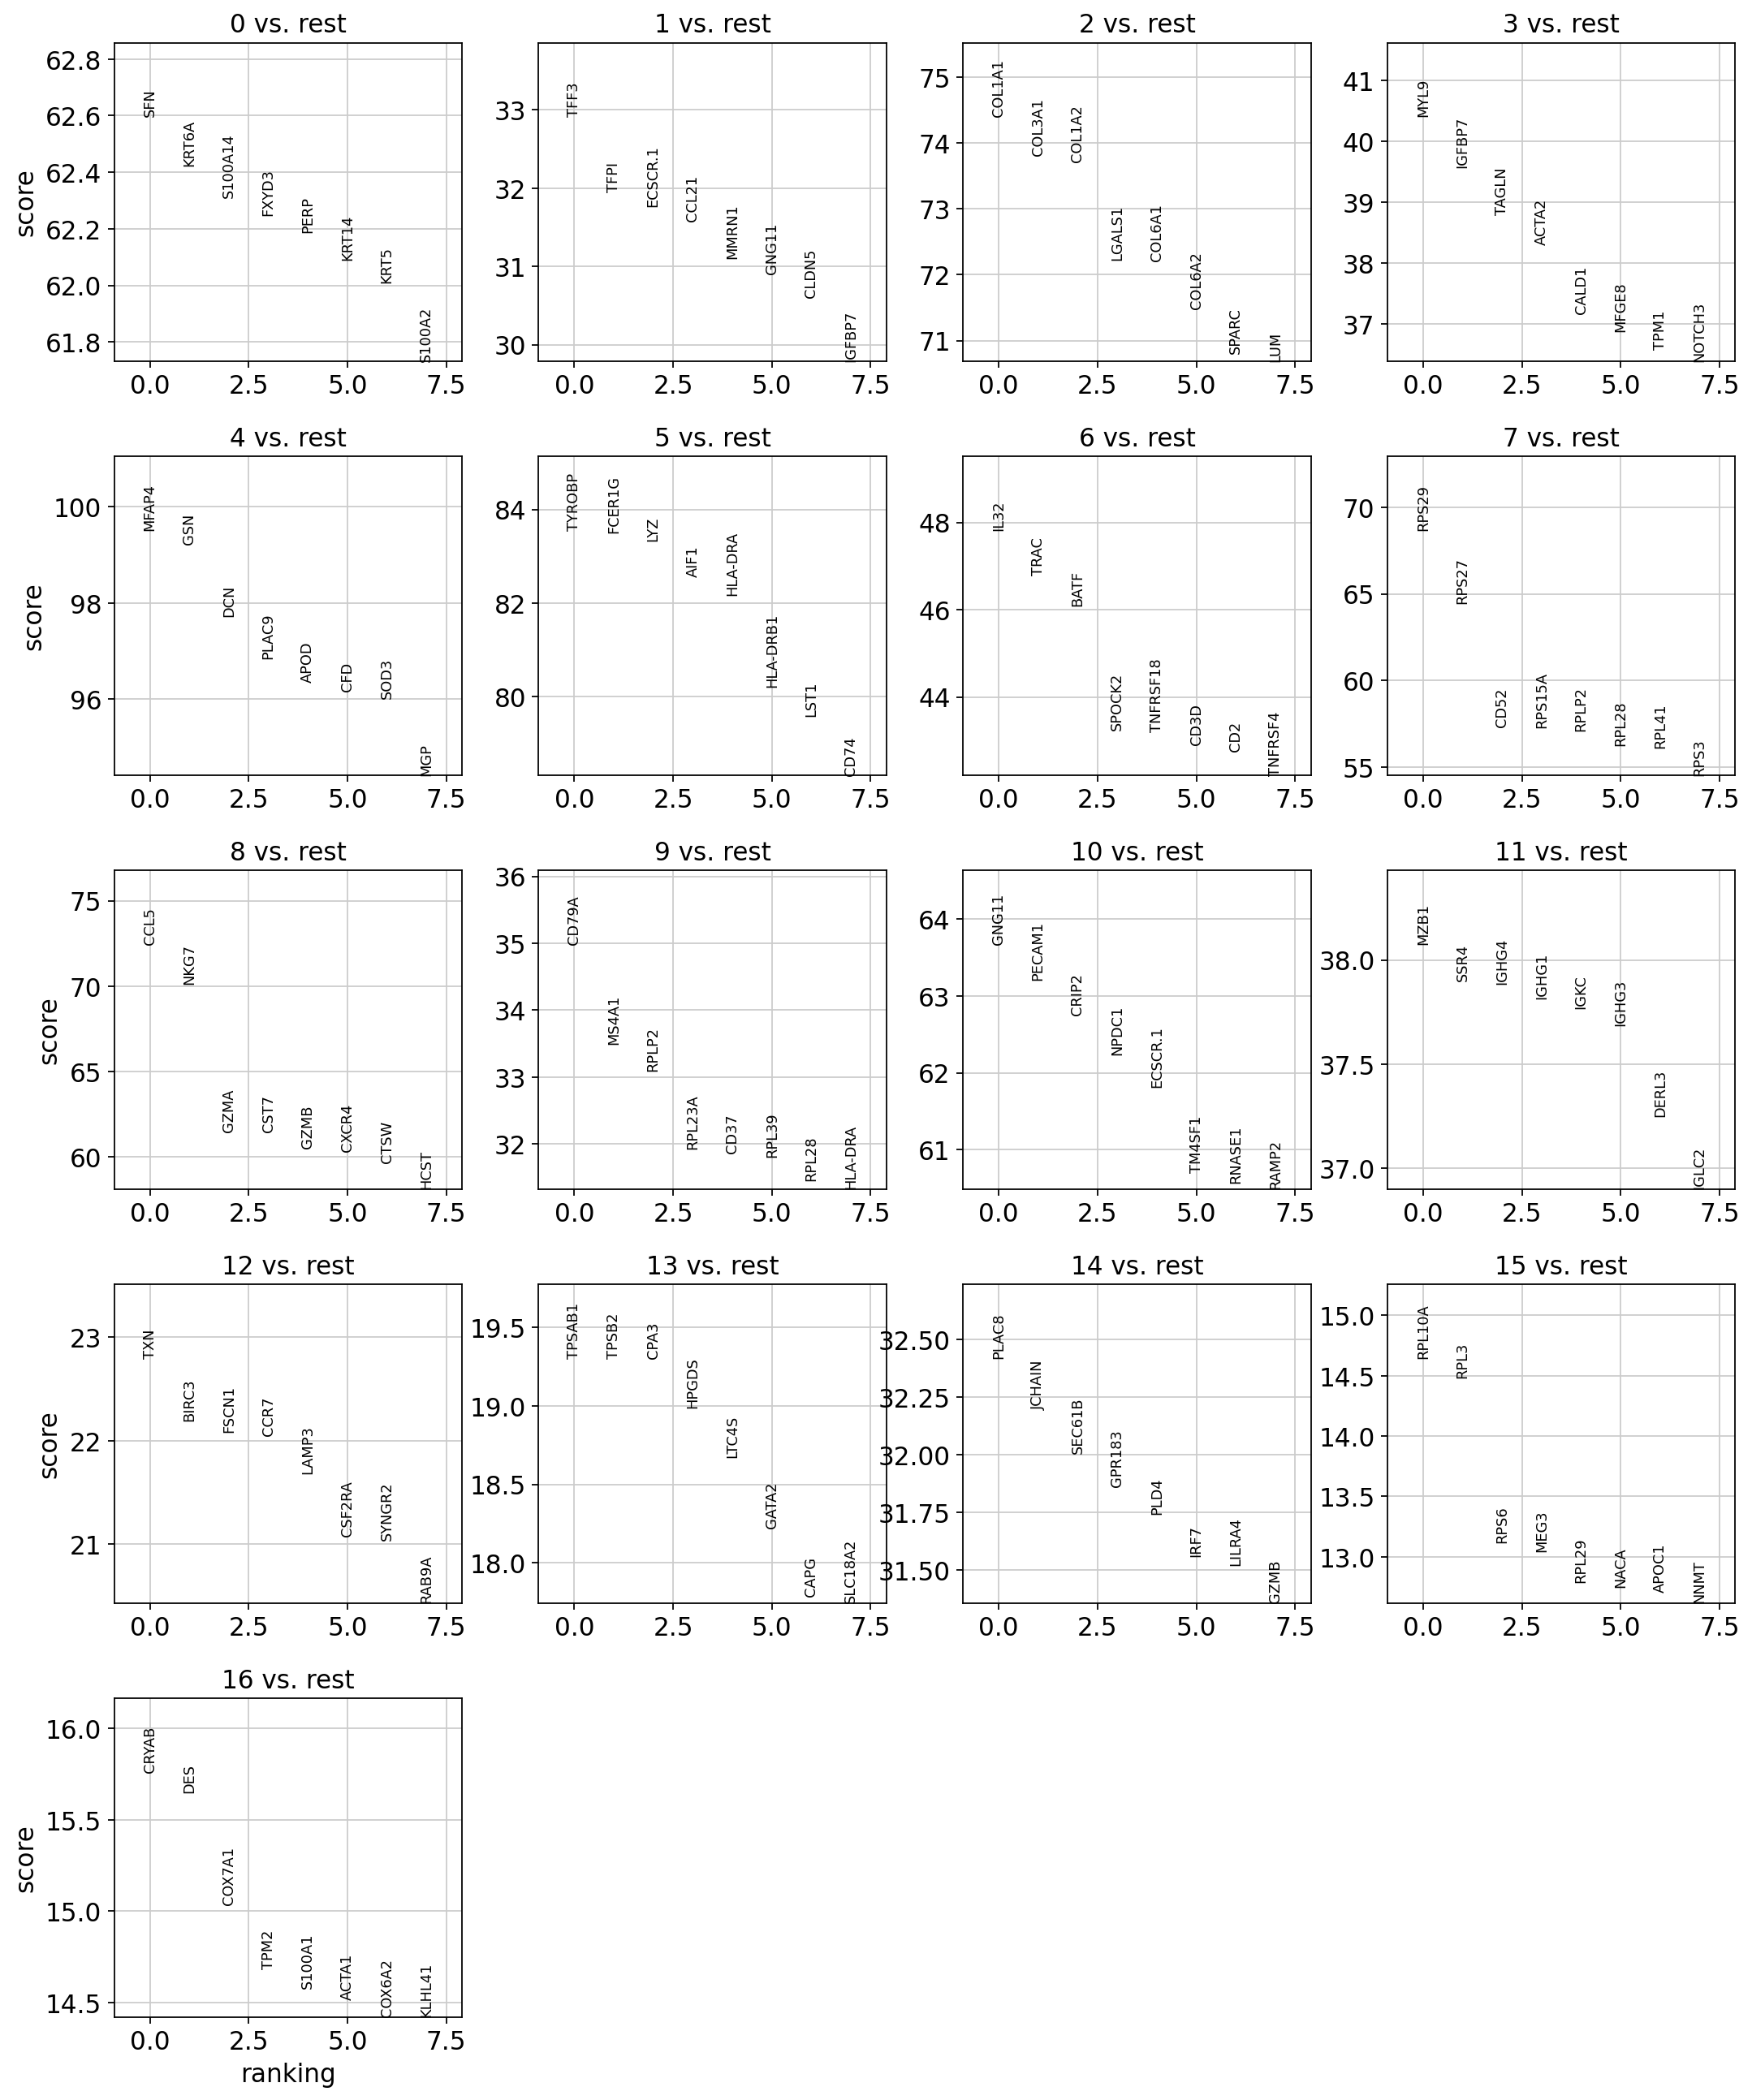

In [ ]:
sc.tl.rank_genes_groups(oral, groupby="leiden_0.5", method="wilcoxon", pts=True)
sc.pl.rank_genes_groups(oral, n_genes=8, sharey=False)

### Annotation notes (my reasoning)

I annotated the leiden_0.5 clusters from marker dotplots before checking the authors'
labels. Most calls held up: cluster 0 as epithelial (KRT5/KRT14/KRT17), 6–8 as one T cell
group, 2 and 4 as fibroblasts, 5 as myeloid, 9 as B cells, 13 as mast and 16 as muscle. I
also chose resolution 0.5 over 0.2 because at 0.2 the myeloid and dendritic cells stay
merged in one cluster.

Three calls were wrong or incomplete. I read the KRT13-high cells inside cluster 0 as the
cancerous fraction, but KRT13 is a differentiation keratin of normal oral mucosa that
cancer usually loses, so these are more likely normal or leukoplakia cells. I planned to
merge clusters 1 and 10 as endothelium, but cluster 1 is a separate island with lower VWF,
which fits lymphatic endothelium. I labelled 14 as plasma cells on JCHAIN alone, although
it lacks CD79A and carries CD68, which fits plasmacytoid dendritic cells; cluster 11
(CD79A+, MZB1+, MS4A1−) is the real plasma cell cluster. I had also grouped 3 with the
fibroblasts despite its weaker collagen, which suggests pericytes instead.

To resolve these I am scoring a second dotplot with lymphatic (LYVE1, PROX1, CCL21),
pericyte (RGS5, MYH11, PDGFRB) and pDC (LILRA4, CLEC4C) markers, running
`rank_genes_groups` on the uncharacterised cluster 15, and splitting KRT13 expression in
cluster 0 by `tissue.type`. Malignant versus normal epithelium is deferred to CNV
inference rather than decided on keratins.

### Clusters 7 and 15: quality check

Clusters 7 and 15 have ribosomal genes at the top of their marker lists. QC metrics per cluster:

In [ ]:
ribo = oral.var_names.str.startswith(("RPS", "RPL"))
counts = oral.layers["counts"]
oral.obs["pct_ribo"] = (
    np.asarray(counts[:, ribo].sum(1)).ravel() / np.asarray(counts.sum(1)).ravel() * 100
)

cols = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_ribo"]
print(oral.obs.groupby("leiden_0.5", observed=True)[cols].median().round(2))

            n_genes_by_counts  total_counts  pct_counts_mt   pct_ribo
leiden_0.5                                                           
0                      5173.5       38359.0           3.65  22.860001
1                      2333.0        7501.0           2.04  24.200001
2                      2945.0       12033.0           3.24  20.620001
3                      2218.0        7107.0           4.04  22.250000
4                      1624.0        4577.0           2.77  24.340000
5                      2192.0        9830.0           2.92  17.190001
6                      1973.0        5881.0           2.10  22.790001
7                      1031.0        3235.0           2.06  34.660000
8                      1297.5        3663.5           2.33  27.760000
9                      1358.0        5106.0           2.99  39.080002
10                     1927.0        5769.0           3.13  25.879999
11                     1759.0       16712.5           1.57   9.200000
12                  

In [ ]:
ct = pd.crosstab(oral.obs["sample.id"], oral.obs["leiden_0.5"])
print(ct[["7", "15"]].sort_values("15", ascending=False).head(8))

leiden_0.5     7  15
sample.id           
N15           19  47
N21          162  23
LP16         431  12
C07           38   8
LP17          26   6
LP33         185   5
N06         1157   3
C30            2   2


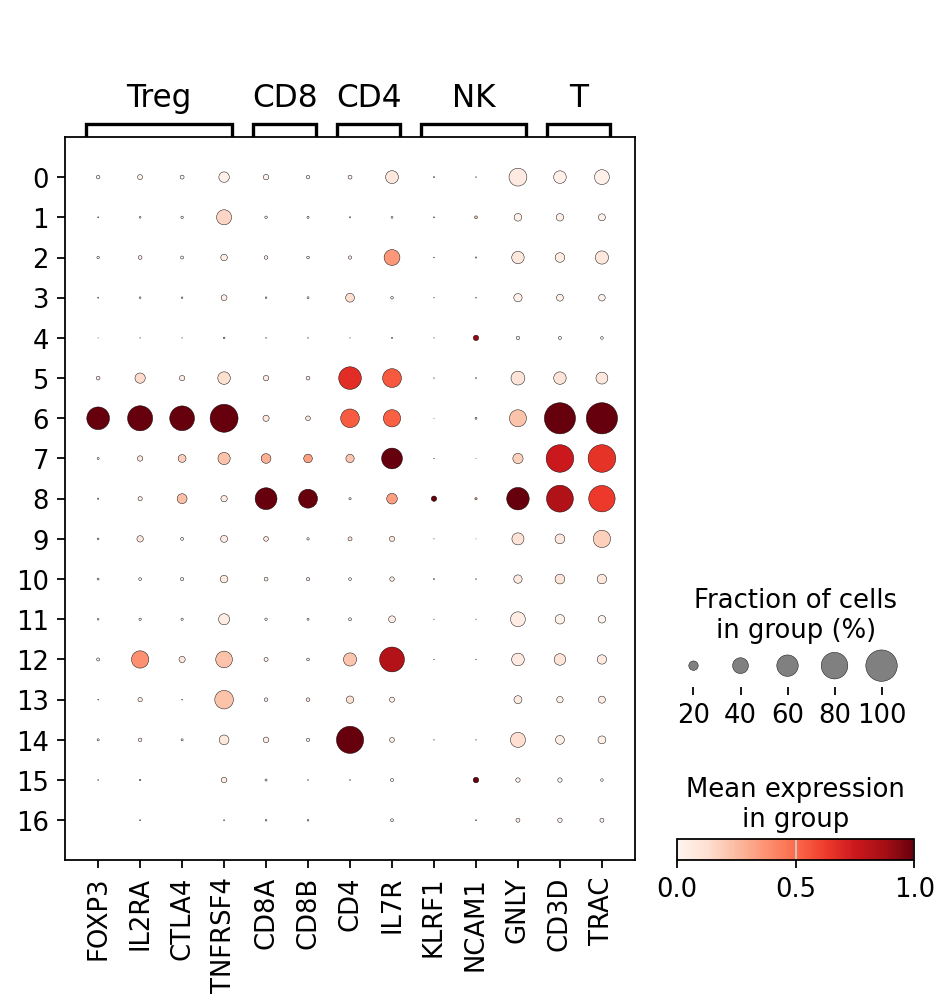

In [ ]:
sc.pl.dotplot(oral, {"Treg": ["FOXP3", "IL2RA", "CTLA4", "TNFRSF4"],
                     "CD8": ["CD8A", "CD8B"], "CD4": ["CD4", "IL7R"],
                     "NK": ["KLRF1", "NCAM1", "GNLY"], "T": ["CD3D", "TRAC"]},
              groupby="leiden_0.5", standard_scale="var")

- **High ribosomal fraction alone does not mean low quality.** Cluster 9 (clean B cells) has the highest
  value (39%), and clusters 7, 8 and 14 are at 28–35%. Small lymphocytes have little cytoplasm, so
  housekeeping transcripts take a larger share of a small library.
- **Cluster 7** is IL7R-high with strong CD3D and TRAC: CD4 T cells (naive/memory), not debris.
- **Cluster 15** is still open. Its QC does not look like dying cells (median mitochondrial 3.4%), it is spread
  across patients (N15, N21, LP16, C07, LP17, LP33…), and it is enriched in normal and leukoplakia tissue.
  Its top genes after removing ribosomal and mitochondrial genes are listed below.

In [ ]:
# Remove housekeeping genes from the marker list so lineage markers become visible
df15 = sc.get.rank_genes_groups_df(oral, group="15")
drop = df15["names"].str.startswith(("RPS", "RPL", "MT-", "MRPS", "MRPL"))
print(df15[~drop].head(25)[["names", "logfoldchanges", "pct_nz_group", "pct_nz_reference"]])
print("\ncluster sizes:\n", oral.obs["leiden_0.5"].value_counts().sort_index())

       names  logfoldchanges  pct_nz_group  pct_nz_reference
3       MEG3        3.749529      0.837838          0.264159
5       NACA        1.112791      1.000000          0.979793
6      APOC1        4.497014      0.792793          0.190845
7       NNMT        3.426085      0.846847          0.362078
8     GNB2L1        0.983014      1.000000          0.990148
10      SGCA        5.591047      0.693694          0.036886
11      CD63        1.766072      1.000000          0.863087
16      MYF5       10.270748      0.648649          0.001558
17      APOE        3.807927      0.801802          0.314195
19      MEST        4.925428      0.675676          0.083440
21    CHRNA1        8.293657      0.630631          0.006873
22    TUBB2B        5.684839      0.639640          0.035420
23    IGFBP5        2.924969      0.801802          0.261272
24  PPP1R14B        2.824763      0.747748          0.313325
25      BTF3        1.019670      1.000000          0.963985
31     CEBPD        2.59

### Final labels, compared with the authors' labels

In [ ]:
names = {
    "0": "Epithelial",
    "1": "Lymphatic endothelial",
    "2": "Fibroblasts (matrix)",
    "3": "Pericytes",
    "4": "Fibroblasts (resting)",
    "5": "Myeloid",
    "6": "CD4 T cells",
    "7": "T cells (ribo-high, check QC)",
    "8": "CD8 T / NK",
    "9": "B cells",
    "10": "Endothelial (blood)",
    "11": "Plasma cells (IgG)",
    "12": "Mature DC (LAMP3+)",
    "13": "Mast cells",
    "14": "pDC",
    "15": "Low quality? (check QC)",
    "16": "Skeletal muscle",
}
oral.obs["my_cell_type"] = oral.obs["leiden_0.5"].map(names).astype("category")
pd.crosstab(oral.obs["my_cell_type"], oral.obs["cell.type"])

cell.type,B_Plasma.cells,Dendritic.cells,Endothelial.cells,Epithelial.cells,Fibroblasts,Macrophages,Malignant.cells,Mast.cells,Myocytes,T.cells
my_cell_type,,,,,,,,,,
Epithelial,15,0,0,131,5,0,1154,2,0,103
Lymphatic endothelial,0,0,370,0,0,0,0,0,0,1
Fibroblasts (matrix),17,0,5,2,2207,15,4,5,0,18
Pericytes,0,0,115,1,497,0,1,0,0,1
Fibroblasts (resting),161,0,50,18,4395,0,9,0,6,8
Myeloid,2,190,13,0,0,2643,0,4,0,10
CD4 T cells,6,0,0,0,0,1,0,0,0,996
"T cells (ribo-high, check QC)",196,4,1,85,0,0,0,1,0,2465
CD8 T / NK,48,1,3,1,0,0,1,0,1,2177


In [ ]:
oral.write_h5ad(RESULTS_DIR / "oral_annotated.h5ad", compression="gzip")

## 11. Next steps

- Remove predicted doublets before DE (see section 4).
- Resolve clusters 7 and 15, and split KRT13 expression in cluster 0 by `tissue.type`.
- Score lymphatic (LYVE1, PROX1, CCL21), pericyte (RGS5, MYH11, PDGFRB) and pDC (LILRA4, CLEC4C) markers to
  confirm clusters 1, 3 and 14.
- CNV inference on epithelial cells to call malignant vs normal epithelium.
- Pseudobulk DE (per sample, raw counts) between tumour and normal epithelium, accounting for ambient RNA.
- Validate candidate markers in independent data (TCGA, spatial transcriptomics) and later by IHC/RNAscope.